In [63]:
import matplotlib.pyplot as plt
import scipy
import numpy as np
from matplotlib.ticker import AutoMinorLocator, AutoLocator, MaxNLocator, MultipleLocator, FixedLocator
import arviz as az

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = 'Times New Roman'

In [2]:
dislo_fitting_param_names = [r'$\text{log}_{10}(\rho_{0}[\text{m}^{-2}])$', r'$\it{p}$', r'$\it{q}$', r'$\it{i}_{\it{s}}$', r'$\it{D}_{\it{a}}$']

pheno_fitting_param_names = [r'$\it{a}$', r'$\it{\xi}_{0}[\text{MPa}]$', r'$\it{\xi}_{\infty}[\text{MPa}]$', r'$\it{h}_{0}^{\it{s-s}}[\text{MPa}]$']

In [3]:
def gaussian(x, mu, sigma, a):
    return a*np.exp(-((x-mu)**2)/(2*(sigma)**2))

def dual_gaussian(x, mu_1, mu_2, sigma_1, sigma_2, a1, a2):
    return a1*np.exp(-((x-mu_1)**2)/(2*sigma_1**2)) + a2*np.exp(-((x-mu_2)**2)/(2*sigma_2**2))

def triple_gaussian(x, mu_1, mu_2, mu_3, sigma_1, sigma_2, sigma_3, a1, a2, a3):
    return a1*np.exp(-((x-mu_1)**2)/(2*sigma_1**2)) + a2*np.exp(-((x-mu_2)**2)/(2*sigma_2**2)) + a3*np.exp(-((x-mu_3)**2)/(2*sigma_3**2))

In [4]:
def find_means_and_stdevs(posterior_vals, gaussian, guess, param_range):
    counts, bins, _ = plt.hist(posterior_vals, bins=100, facecolor = 'b')
    xbins = bins[:-1] + (bins[1]-bins[0])/2
    pars, covs = scipy.optimize.curve_fit(gaussian, xbins, counts, p0 = guess)
    param_vals = np.linspace(param_range[0], param_range[1], 1000)
    plt.plot(param_vals, gaussian(param_vals, *pars))
    if gaussian == gaussian:
        means = pars[0]
        stdevs = pars[1]
    if gaussian == dual_gaussian:
        means = [pars[0], pars[1]]
        stdevs = [pars[2]], pars[3]
    if gaussian == triple_gaussian:
        means = [pars[0], pars[1], pars[2]]
        stdevs = [pars[3], pars[4], pars[5]]
    return means, stdevs

# Load posterior distributions

In [7]:
dislo_inf_data = az.from_netcdf("../../parameter_traces/dislotwin_parameter_traces_2_percent_strain_err_50k_draws_second_year_report.netcdf")
pheno_inf_data = az.from_netcdf("../../parameter_traces/phenopowerlaw_parameter_traces_2_percent_strain_err_50k_draws_second_year_report.netcdf")

In [8]:
X_posterior_dislo = np.array([np.array(dislo_inf_data.posterior[x]).flatten() for x in dislo_fitting_param_names]).T
X_mode_dislo = np.array([scipy.stats.mode(X_posterior_dislo[:,i])[0] for i in range(len(dislo_fitting_param_names))])
X_mean_dislo = np.array([np.mean(X_posterior_dislo[:,i]) for i in range(len(dislo_fitting_param_names))])
X_std_dislo = np.array([np.std(X_posterior_dislo[:,i]) for i in range(len(dislo_fitting_param_names))])

S_mode_dislo = scipy.stats.mode(np.array(dislo_inf_data.posterior.sigma).flatten())

In [9]:
X_posterior_pheno = np.array([np.array(pheno_inf_data.posterior[x]).flatten() for x in pheno_fitting_param_names]).T
X_mode_pheno = np.array([scipy.stats.mode(X_posterior_pheno[:,i])[0] for i in range(len(pheno_fitting_param_names))])
X_mean_pheno = np.array([np.mean(X_posterior_pheno[:,i]) for i in range(len(pheno_fitting_param_names))])
X_std_pheno = np.array([np.std(X_posterior_pheno[:,i]) for i in range(len(pheno_fitting_param_names))])

S_mode_pheno = scipy.stats.mode(np.array(pheno_inf_data.posterior.sigma).flatten())

# Find means and stdevs

Dislotwin

(np.float64(8.4082420191247), np.float64(0.06046671466000966))


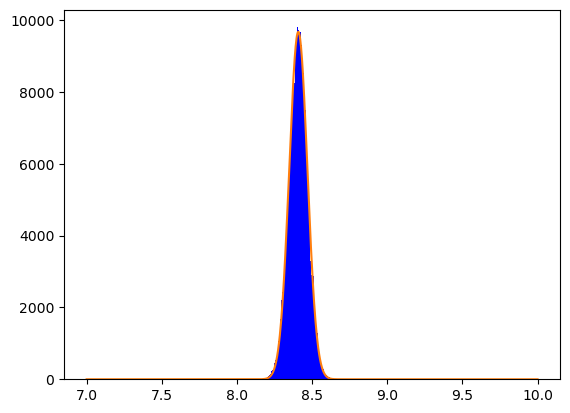

In [10]:
p0_rho_0 = [8.5, 0.1, 3000]
rho_0_mean_and_stdev = find_means_and_stdevs(X_posterior_dislo[:,0], gaussian, p0_rho_0, [7,10])
print(rho_0_mean_and_stdev)

(np.float64(0.34657203679829707), np.float64(0.02411242043893651))


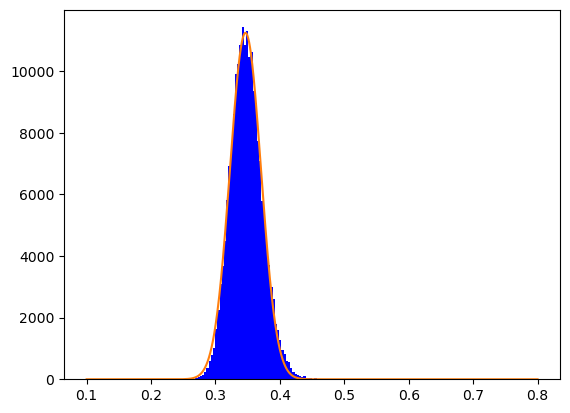

In [11]:
p0_p = [0.3, 0.05, 3000]
p_mean_and_stdev = find_means_and_stdevs(X_posterior_dislo[:,1], gaussian, p0_p, [0.1,0.8])
print(p_mean_and_stdev)

(np.float64(1.488069010238742), np.float64(0.01616747735474147))


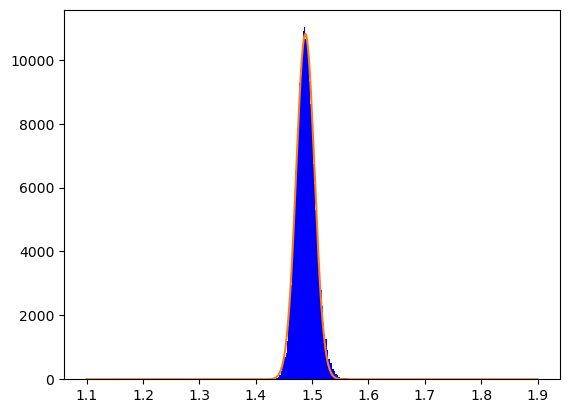

In [12]:
p0_q = [1.5, 0.05, 3000]
q_mean_and_stdev = find_means_and_stdevs(X_posterior_dislo[:,2], gaussian, p0_q, [1.1,1.9])
print(q_mean_and_stdev)

(np.float64(18.656516300871978), np.float64(0.15832249754900155))


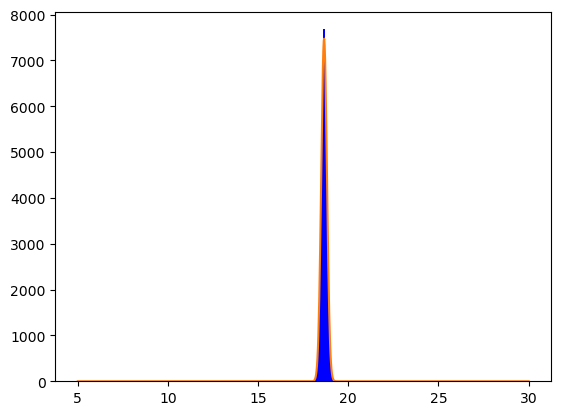

In [13]:
p0_i_s = [18.5, 0.2, 3000]
i_s_mean_and_stdev = find_means_and_stdevs(X_posterior_dislo[:,3], gaussian, p0_i_s, [5,30])
print(i_s_mean_and_stdev)

(np.float64(5.9800687484319495), np.float64(0.19813017726340196))


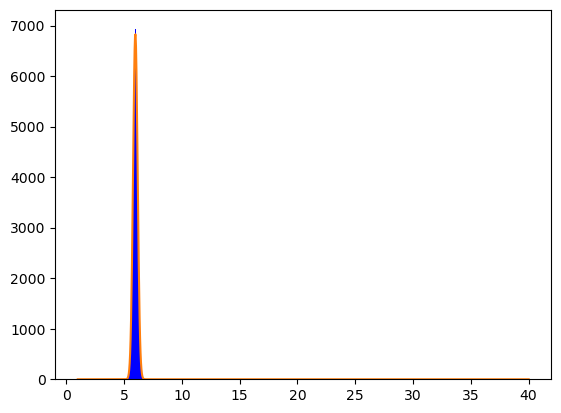

In [14]:
p0_D_a = [5, 0.1, 3000]
D_a_mean_and_stdev = find_means_and_stdevs(X_posterior_dislo[:,4], gaussian, p0_D_a, [1,40])
print(D_a_mean_and_stdev)

In [15]:
S_dislo_posterior = np.array(dislo_inf_data.posterior['sigma']).flatten()

(np.float64(0.0464188895054221), np.float64(0.002576978577619757))


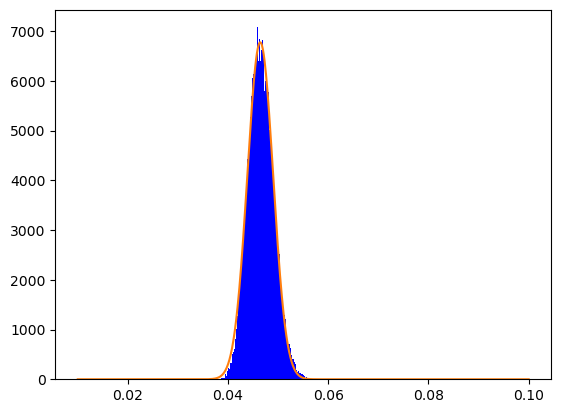

In [16]:
S_dislo_mean_and_stdev = find_means_and_stdevs(S_dislo_posterior, gaussian, [0.045, 0.005, 3000], param_range=[0.01, 0.1])
print(S_dislo_mean_and_stdev)

Phenopowerlaw

([np.float64(1.057229611938016), np.float64(1.391839756928533), np.float64(2.0455617467135188)], [np.float64(0.12233077565883961), np.float64(0.15597094626729968), np.float64(0.33373095066702185)])


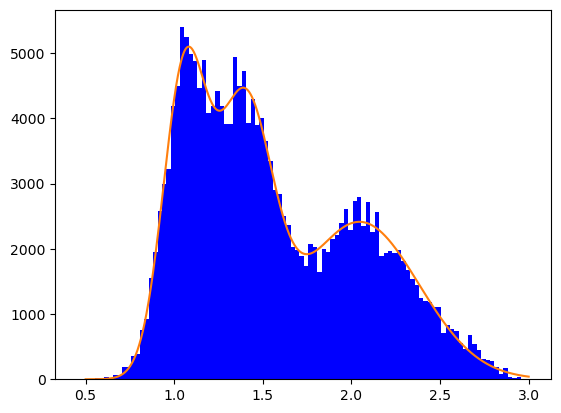

In [17]:
p0_a = [1, 1.5, 2, 0.1, 0.1, 0.1, 5000, 4000, 3000]
a_means_and_stdevs = find_means_and_stdevs(X_posterior_pheno[:,0], triple_gaussian, p0_a, [0.5,3])
print(a_means_and_stdevs)

(np.float64(2.1157748057658714), np.float64(0.5270720566287039))


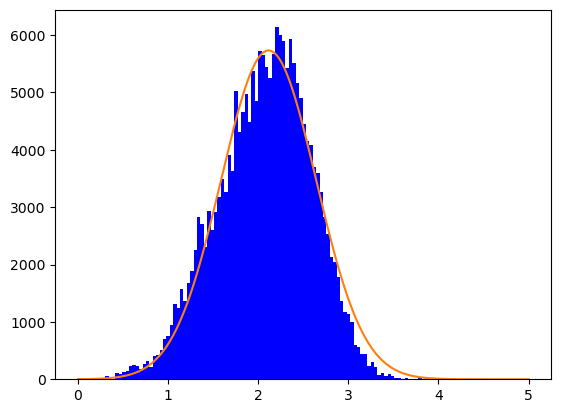

In [18]:
p0_xi_0 = [2, 0.2, 7000]
xi_0_mean_and_stdev = find_means_and_stdevs(X_posterior_pheno[:,1], gaussian, p0_xi_0, [0,5])
print(xi_0_mean_and_stdev)

([np.float64(142.5790011963368), np.float64(215.00864092745027), np.float64(296.31524287962634)], [np.float64(9.057801794570047), np.float64(19.669918973538017), np.float64(15.397513834526102)])


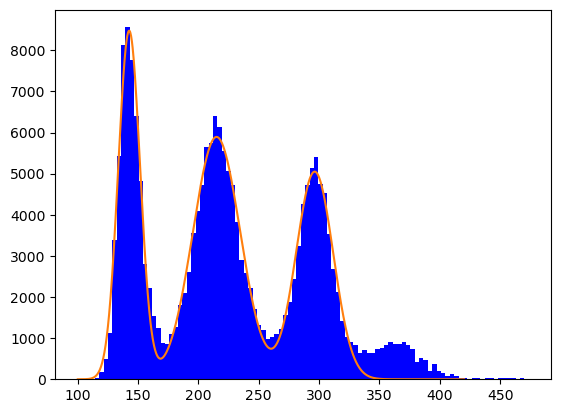

In [19]:
p0_xi_inf = [150, 200, 300, 1, 1, 1, 7200, 4000, 4000]
xi_inf_means_and_stdevs = find_means_and_stdevs(X_posterior_pheno[:,2], triple_gaussian, p0_xi_inf, [100,420])
print(xi_inf_means_and_stdevs)

(np.float64(315.9437554128178), np.float64(16.216938327161248))


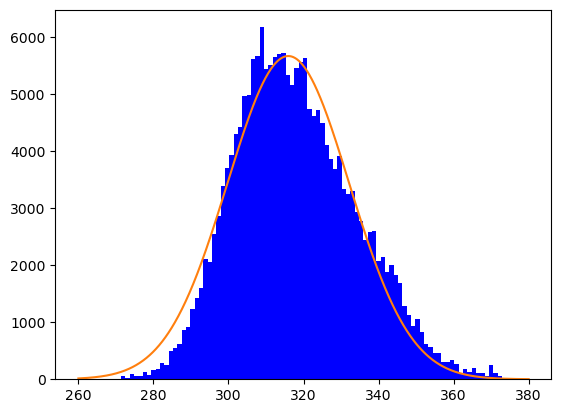

In [20]:
p0_h_0 = [300, 1, 6000]

h_0_mean_and_stdev = find_means_and_stdevs(X_posterior_pheno[:,3], gaussian, p0_h_0, [260,380])
print(h_0_mean_and_stdev)

In [21]:
S_pheno_posterior = np.array(pheno_inf_data.posterior['sigma']).flatten()

(np.float64(0.09622441625786665), np.float64(0.005376663396923599))


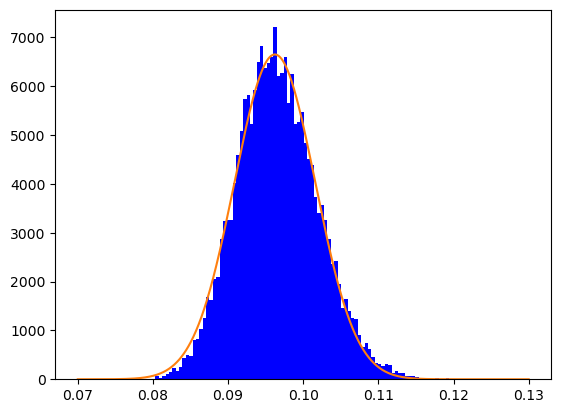

In [22]:
p0_S = [0.1, 0.01, 6000]
S_pheno_mean_and_stdev = find_means_and_stdevs(S_pheno_posterior, gaussian, p0_S, param_range=[0.07, 0.13])
print(S_pheno_mean_and_stdev)

# Galaxy plots

Dislotwin

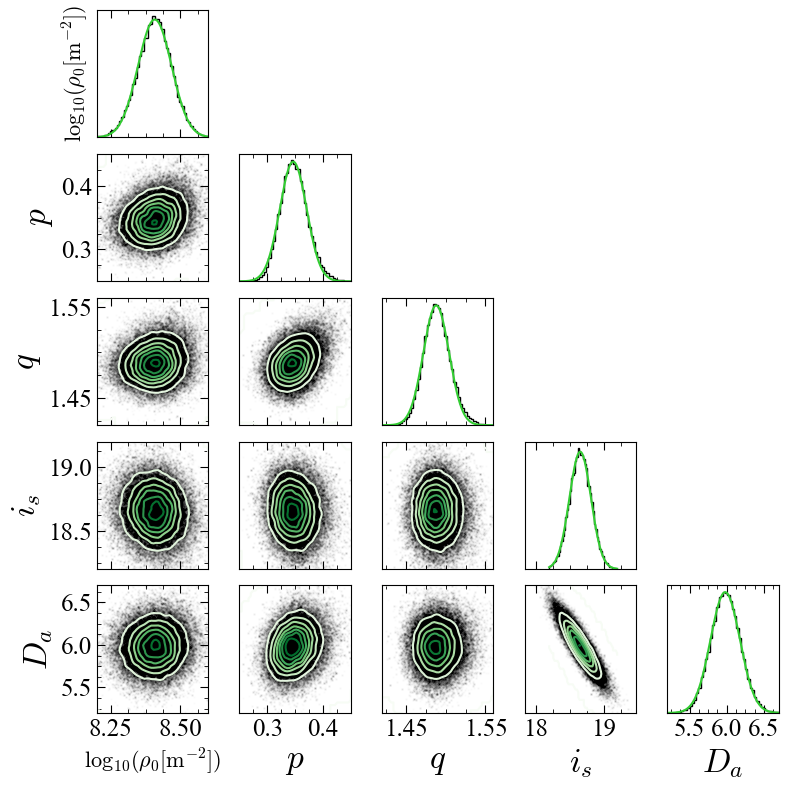

In [67]:
fig_galaxy,ax_galaxy=plt.subplots(len(X_posterior_dislo[0]),len(X_posterior_dislo[0]),figsize=(8,8), sharex='col')
#fig_galaxy.suptitle(f'{1-p}{1-p}1 loading')

for i in range(len(dislo_fitting_param_names)):

    if i == 0 :
            #dislo_param_vals = np.linspace(dislo_surrogates[0].parameter_range[j][0], dislo_surrogates[0].parameter_range[j][1], 1000)
        dislo_param_vals_i = np.linspace(8.2,8.6, 1000)
            
    elif i == 1:
        dislo_param_vals_i = np.linspace(0.25,0.45, 1000)
            #ax_galaxy[j,i].set_xlim(8.2, 8.6)
            
    elif i == 2:
        dislo_param_vals_i = np.linspace(1.42,1.56, 1000)

    elif i == 3:
        dislo_param_vals_i = np.linspace(18.2, 19.2, 1000)

    elif i == 4:
        dislo_param_vals_i = np.linspace(5.2, 6.7, 1000)

    for j in range(len(dislo_fitting_param_names)):

        if j == 0 :
            #dislo_param_vals = np.linspace(dislo_surrogates[0].parameter_range[j][0], dislo_surrogates[0].parameter_range[j][1], 1000)
            dislo_param_vals_j = np.linspace(8.2,8.6, 1000)
            
        elif j == 1:
            dislo_param_vals_j = np.linspace(0.25,0.45, 1000)
            #ax_galaxy[j,i].set_xlim(8.2, 8.6)
            
        elif j == 2:
            dislo_param_vals_j = np.linspace(1.42,1.56, 1000)

        elif j == 3:
            dislo_param_vals_j = np.linspace(18.2, 19.2, 1000)

        elif j == 4:
            dislo_param_vals_j = np.linspace(5.2, 6.7, 1000)

        if i==j:

            dislo_param_counts, dislo_param_bins, _ = ax_galaxy[j,i].hist(X_posterior_dislo[:,j],range = (min(dislo_param_vals_j), max(dislo_param_vals_j)), bins=50, facecolor = 'None', edgecolor = 'k', histtype = 'step')
            dislo_param_xbins = dislo_param_bins[:-1] + (dislo_param_bins[1]-dislo_param_bins[0])/2
            if j == 0:
                p0 = p0_rho_0
            if j == 1:
                p0 = p0_p
            if j == 2:
                p0 = p0_q
            if j == 3:
                p0 = p0_i_s
            if j == 4:
                p0 = p0_D_a

            dislo_pars, dislo_covs = scipy.optimize.curve_fit(gaussian, dislo_param_xbins, dislo_param_counts, p0)

            #if j == 0 :
            #    #dislo_param_vals = np.linspace(dislo_surrogates[0].parameter_range[j][0], dislo_surrogates[0].parameter_range[j][1], 1000)
            #    dislo_param_vals = np.linspace(8.2,8.6, 1000)
            
            #elif j == 1:
            #    dislo_param_vals = np.linspace(0.25,0.45, 1000)
            #    #ax_galaxy[j,i].set_xlim(8.2, 8.6)
            
            #elif j == 2:
            #    dislo_param_vals = np.linspace(1.44,1.56, 1000)

            #elif j == 3:
            #    dislo_param_vals = np.linspace(18.2, 19.2, 1000)

            #elif j == 4:
            #    dislo_param_vals = np.linspace(5.2, 6.7, 1000)

            ax_galaxy[j,i].plot(dislo_param_vals_j, gaussian(dislo_param_vals_j, *dislo_pars), 'limegreen')
            ax_galaxy[j,i].set_xlim(min(dislo_param_vals_j), max(dislo_param_vals_j))
            #    ax_galaxy[j,i].plot(dislo_param_vals, fit_type(dislo_param_vals, *dislo_pars), 'limegreen')

            if j < 3:
                ax_galaxy[j,i].set_yticklabels([])
                ax_galaxy[j,i].set_xticklabels([])
                ax_galaxy[j,i].set_yticks([])

            else:
                ax_galaxy[j,i].set_yticklabels([])
                ax_galaxy[j,i].set_yticks([])
    

        else:
            counts,ybins,xbins,image  = ax_galaxy[j,i].hist2d(X_posterior_dislo[:,i],X_posterior_dislo[:,j],bins=50, range = [[min(dislo_param_vals_i),max(dislo_param_vals_i)],[min(dislo_param_vals_j),max(dislo_param_vals_j)]], cmap='binary')#,norm='log')
            ax_galaxy[j,i].clear()
            
            ax_galaxy[j,i].plot(X_posterior_dislo[:,i],X_posterior_dislo[:,j], lw=0,ls='-',marker='.',markersize=1.0,color='k',alpha=0.02)

            counts = scipy.ndimage.gaussian_filter(counts, sigma=1.0)

            ax_galaxy[i,j].contour(counts,extent=[xbins.min(),xbins.max(),ybins.min(),ybins.max()],cmap='Greens',antialiased=True,levels=7)

            ax_galaxy[j,i].set_ylim(min(dislo_param_vals_j), max(dislo_param_vals_j))

        ax_galaxy[j,i].xaxis.set_minor_locator(AutoMinorLocator(4))
        ax_galaxy[j,i].yaxis.set_minor_locator(AutoMinorLocator(4))
                    
        ax_galaxy[j,i].tick_params(which = 'both', direction = 'in', top = True)
        ax_galaxy[j,i].tick_params(which = 'minor', length = 3)
        ax_galaxy[j,i].tick_params(which = 'major', length = 6, labelsize = 18)

        if j != i:
            ax_galaxy[j,i].tick_params(which = 'both', direction = 'in', right = True)

        if j > i:
            fig_galaxy.delaxes(ax_galaxy[i,j])

        if j > 0:
            ax_galaxy[i,j].set_yticks([])

        if j==0:
            ax_galaxy[i,j].set_ylabel(dislo_fitting_param_names[i], math_fontfamily = 'cm', fontsize = 24)

        if i == 0 and j == 0:
            ax_galaxy[i,j].set_ylabel(r'$\text{log}_{10}(\rho_{0} [\text{m}^{-2}])$', math_fontfamily = 'cm', fontsize = 16)

        if i==len(X_posterior_dislo[0])-1:
            ax_galaxy[i,j].set_xlabel(dislo_fitting_param_names[j], math_fontfamily = 'cm', fontsize = 24)

        if i == len(X_posterior_dislo[0])-1 and j == 0:
            ax_galaxy[i,j].set_xlabel(r'$\text{log}_{10}(\rho_{0} [\text{m}^{-2}])$', math_fontfamily = 'cm', fontsize = 16)

        if i == len(X_posterior_dislo[0])-1 and j == 2:
            ax_galaxy[i,j].xaxis.set_major_locator(FixedLocator([1.45,1.55]))

        if i == 2 and j == 0:
            ax_galaxy[i,j].yaxis.set_major_locator(FixedLocator([1.45,1.55]))
            
            
        else:            
            #ax[i,j].set_xlim(0.5,1.0)
            pass

#ax_galaxy[0,0].set_yticklabels([])
#ax_galaxy[0,0].set_yticks([])

fig_galaxy.tight_layout()

plt.savefig('./dislotwin_galaxy_plot_parallel_calibration_2_percent_strain_err_second_year_report_poster_label_sizes.png', dpi = 800)

Phenopowerlaw

In [73]:
pheno_param_ranges = np.array([[0.1, 3], [0, 40], [40, 500], [100, 400]])

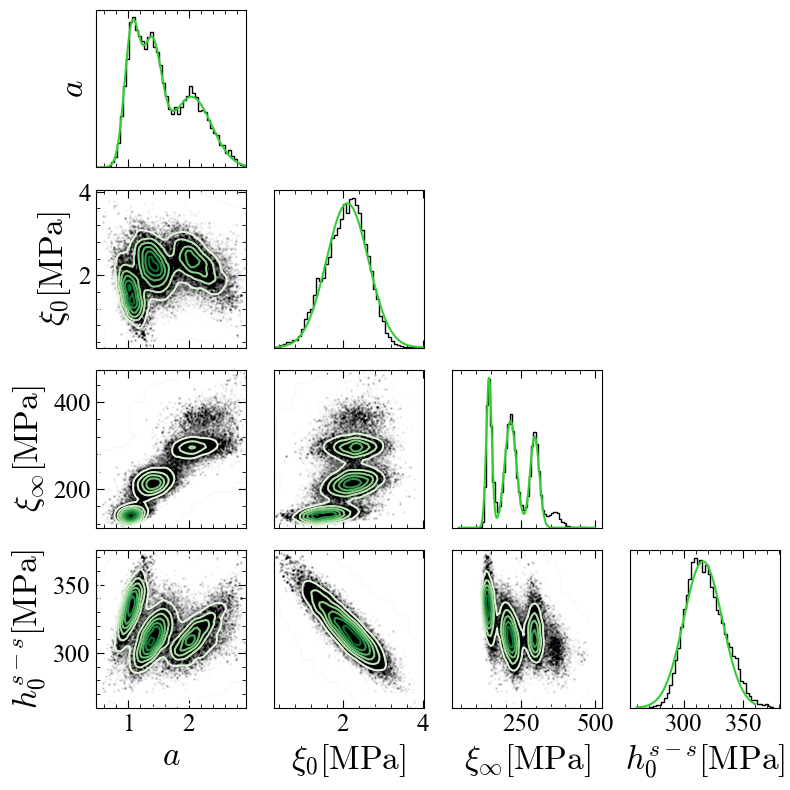

In [77]:
fig_galaxy,ax_galaxy=plt.subplots(len(X_posterior_pheno[0]),len(X_posterior_pheno[0]),figsize=(8,8), sharex='col')
#fig_galaxy.suptitle(f'{1-p}{1-p}1 loading')

for i in range(len(pheno_fitting_param_names)):

    #if i == 2:
        #pheno_param_vals_i = np.linspace(110, 420, 1000)

    for j in range(len(pheno_fitting_param_names)):

        #if j == 2:
            #pheno_param_vals_j = np.linspace(110, 420, 1000)

        if i==j:
            #if j == 2:
            #    pheno_param_counts, pheno_param_bins, _ = ax_galaxy[j,i].hist(X_posterior_pheno[:,j],bins=50, range = (min(pheno_param_vals_j), max(pheno_param_vals_j)), facecolor = 'None', edgecolor = 'k', histtype = 'step')
            #else:
            pheno_param_counts, pheno_param_bins, _ = ax_galaxy[j,i].hist(X_posterior_pheno[:,j],bins=50, facecolor = 'None', edgecolor = 'k', histtype = 'step')
            
            pheno_param_xbins = pheno_param_bins[:-1] + (pheno_param_bins[1]-pheno_param_bins[0])/2
            if j == 0:
                fit_type = triple_gaussian
                p0 = p0_a
            if j == 1:
                fit_type = gaussian
                p0 = p0_xi_0
            if j == 2:
                fit_type = triple_gaussian
                p0 = p0_xi_inf
            if j == 3:
                fit_type = gaussian
                p0 = p0_h_0

            pheno_pars, pheno_covs = scipy.optimize.curve_fit(fit_type, pheno_param_xbins, pheno_param_counts, p0)

            if j < 3:
                pheno_param_vals = np.linspace(pheno_param_ranges[j][0], pheno_param_ranges[j][1], 1000)
                ax_galaxy[j,i].plot(pheno_param_vals, fit_type(pheno_param_vals, *pheno_pars), 'limegreen')

            else:
                pheno_param_vals = np.linspace(260, 360, 1000)
                ax_galaxy[j,i].plot(pheno_param_vals, fit_type(pheno_param_vals, *pheno_pars), 'limegreen')

            if j < 2:
                ax_galaxy[j,i].set_yticklabels([])
                ax_galaxy[j,i].set_xticklabels([])
                ax_galaxy[j,i].set_yticks([])

            else:
                ax_galaxy[j,i].set_yticklabels([])
                ax_galaxy[j,i].set_yticks([])
    

        else:
            #if j == 2:
            #    counts,ybins,xbins,image  = ax_galaxy[j,i].hist2d(X_posterior_pheno[:,i],X_posterior_pheno[:,j],bins=50, range = [[pheno_surrogates[0].parameter_range[i][0], pheno_surrogates[0].parameter_range[i][1]], [min(pheno_param_vals_j),max(pheno_param_vals_j)]], cmap='binary')
            
            #if i == 2:
            #    counts,ybins,xbins,image  = ax_galaxy[j,i].hist2d(X_posterior_pheno[:,i],X_posterior_pheno[:,j],bins=50, range = [[min(pheno_param_vals_i),max(pheno_param_vals_i)],[pheno_surrogates[0].parameter_range[j][0], pheno_surrogates[0].parameter_range[j][1]]], cmap='binary')
            
            #else:
            counts,ybins,xbins,image  = ax_galaxy[j,i].hist2d(X_posterior_pheno[:,i],X_posterior_pheno[:,j],bins=50,cmap='binary')#,norm='log')
            ax_galaxy[j,i].clear()
            
            ax_galaxy[j,i].plot(X_posterior_pheno[:,i],X_posterior_pheno[:,j],lw=0,ls='-',marker='.',markersize=1.0,color='k',alpha=0.02)

            counts = scipy.ndimage.gaussian_filter(counts, sigma=1.0)

            ax_galaxy[i,j].contour(counts,extent=[xbins.min(),xbins.max(),ybins.min(),ybins.max()],cmap='Greens',antialiased=True,levels=7)

        ax_galaxy[j,i].xaxis.set_minor_locator(AutoMinorLocator(5))
        ax_galaxy[j,i].yaxis.set_minor_locator(AutoMinorLocator(5))

        ax_galaxy[j,i].xaxis.set_major_locator(AutoLocator())
        ax_galaxy[j,i].yaxis.set_major_locator(AutoLocator())
                    
        ax_galaxy[j,i].tick_params(which = 'both', direction = 'in', top = True)
        ax_galaxy[j,i].tick_params(which = 'minor', length = 3)
        ax_galaxy[j,i].tick_params(which = 'major', length = 6, labelsize = 18)

        if j != i:
            ax_galaxy[j,i].tick_params(which = 'both', direction = 'in', right = True)

        if j > i:

            fig_galaxy.delaxes(ax_galaxy[i,j])

        if j > 0:
            ax_galaxy[i,j].set_yticks([])

        if j < 2:
            pass
            #ax[i,j].set_xlim(-0.5,0.5)

        if j==0:
            ax_galaxy[i,j].set_ylabel(pheno_fitting_param_names[i], math_fontfamily = 'cm', fontsize = 24)

        if i==len(X_posterior_pheno[0])-1:
            ax_galaxy[i,j].set_xlabel(pheno_fitting_param_names[j], math_fontfamily = 'cm', fontsize = 24)
            
        else:            
            #ax[i,j].set_xlim(0.5,1.0)
            pass

ax_galaxy[0,0].set_yticklabels([])
ax_galaxy[0,0].set_yticks([])

fig_galaxy.tight_layout()

plt.savefig('./phenopowerlaw_galaxy_plot_parallel_calibration_2_percent_strain_err_alpha_002_second_year_report_poster_label_sizes.png', dpi=800)